# 03 · The recommendation system

The deck's recommender, in one sentence: take a user's ~150 songs, average them into a
single summary vector, cosine it against a 600k-song database, return the top 10.

That sentence contains three separate bugs. This notebook measures each one, and the
first is considerably worse than "the numbers are a bit off" — it turns out the
original similarity function had almost no ability to tell any two songs apart.

In [1]:
import sys, warnings
sys.path.insert(0, "../src")
warnings.filterwarnings("ignore")

import numpy as np, pandas as pd, matplotlib.pyplot as plt
from lovify_ml import schema as S, data, synthetic as syn, features as F, recommend as R, viz

pd.set_option("display.width", 200, "display.max_columns", 40)

catalog = data.load_catalog(n_synthetic=8000)
listens, taste = data.load_listens(catalog, n_users=120, tracks_per_user=150)

print(f"\ncatalog {len(catalog):,} tracks  ·  {listens[S.USER_ID].nunique()} users  "
      f"·  {len(listens):,} (user, track) rows")

[data] SYNTHETIC catalog (8,000 tracks). Drop a Kaggle dump at /Users/akintunjisule/Desktop/AIM-Music-Matching/ml/data/raw/tracks.csv to use real songs.
[data] SYNTHETIC users. Drop real histories at /Users/akintunjisule/Desktop/AIM-Music-Matching/ml/data/raw/listens.csv to use yours.



catalog 8,000 tracks  ·  120 users  ·  18,000 (user, track) rows


## 1 · The scaling bug

Notebook 00 showed that `duration_ms` carries essentially 100% of the variance in the
raw feature columns. Here is what that does to a cosine similarity.

Start with the deck's exact configuration — no scaling, one mean vector — and look at
what it recommends.

In [2]:
user = listens[listens[S.USER_ID] == listens[S.USER_ID].iloc[0]]
raw_rec = R.Recommender(catalog, scale_features=False)
raw_top = raw_rec.recommend(user, n=10)

raw_top[[S.TRACK_NAME, S.ARTIST, S.GENRE, "duration_ms", "tempo",
         "energy", "valence", "score"]]

,track_name,artist,genre,duration_ms,tempo,energy,valence,score
0,Fynox Noxsol,Sevilamar Marventa,edm,237024.460298,119.838825,0.939707,0.563286,1.0
1,Taazasol Tasol,Venriarin Rinkenquo,indie,297059.138376,150.706761,0.413163,0.485854,1.0
2,Azaquo Quonymria,Virin Ilakendro,rnb,219875.629429,111.790278,0.450383,0.589428,1.0
3,Marila Viquo,Kenquo Kenta,pop,205248.945462,103.849233,0.720991,0.484207,1.0
4,Azariamar Vextorsev,Kenven Riata,pop,247825.568611,125.381821,0.703898,0.547802,1.0
5,Azarinaza Vexkenmel,Taaza Azariavex,latin,197487.591480,99.831427,0.731676,0.705097,1.0
6,Nymvenven Fyvendro,Vensol Rinventa,pop,243350.396165,123.283516,0.931309,0.512388,1.0
7,Kensol Lokennox,Solrinvi Azaven,rnb,284227.575474,144.596571,0.266809,0.525642,1.0
8,Sevlo Losevaza,Fykenmel Dromar,latin,220259.188740,111.121103,0.813115,0.606881,1.0
9,Ilalota Noxken,Quotorsol Fyfy,indie,262302.920663,133.469888,0.539915,0.576513,1.0


Two things to notice.

The `score` column is 1.0 for every row. Not 0.99 — 1.0, to the precision pandas
prints. And the recommendations span six different genres with energies from 0.27 to
0.94, which is not what "the ten most similar songs" should look like.

Print the scores at full precision and the problem becomes obvious.

In [3]:
q = raw_rec.mean_vector(user)
scores = raw_rec._scores(q)

print("top-10 cosine scores, 12 decimal places:")
for v in np.sort(scores)[::-1][:10]:
    print(f"   {v:.12f}")

print()
print("cosine score across the ENTIRE catalog:")
print(f"   minimum : {scores.min():.9f}")
print(f"   median  : {np.median(scores):.9f}")
print(f"   maximum : {scores.max():.12f}")
print(f"   full dynamic range over {len(catalog):,} songs: {scores.max()-scores.min():.6f}")
print()
print(f"   songs scoring above 0.9999   : {(scores > 0.9999).mean():.1%} of the catalog")
print(f"   songs scoring above 0.999999 : {(scores > 0.999999).mean():.1%} of the catalog")

top-10 cosine scores, 12 decimal places:
   0.999999999997
   0.999999999996
   0.999999999995
   0.999999999995
   0.999999999995
   0.999999999995
   0.999999999994
   0.999999999994
   0.999999999994
   0.999999999994

cosine score across the ENTIRE catalog:
   minimum : 0.999444392
   median  : 0.999999992
   maximum : 0.999999999997
   full dynamic range over 8,000 songs: 0.000556

   songs scoring above 0.9999   : 99.8% of the catalog
   songs scoring above 0.999999 : 99.1% of the catalog


**99% of the catalog is "above 0.999999 similar" to this user.** The top ten are
separated from each other in the twelfth decimal place.

This is not a recommender that is biased toward long songs. It is a recommender whose
similarity function has saturated — it returns 1.0 for almost every song in the
database, and the ranking among them is decided by differences far too small to mean
anything musical.

The cause is mechanical:

In [4]:
Xr = catalog[S.AUDIO_FEATURES].to_numpy(float)
norms = np.linalg.norm(Xr, axis=1)

print(f"mean vector length |v|      : {norms.mean():,.0f}")
print(f"mean duration_ms            : {catalog['duration_ms'].mean():,.0f}")
print(f"correlation between the two : {np.corrcoef(norms, catalog['duration_ms'])[0,1]:.8f}")

mean vector length |v|      : 241,643
mean duration_ms            : 241,643
correlation between the two : 1.00000000


The length of every song's feature vector *is* its `duration_ms`, to eight
decimal places. Every vector therefore points in almost exactly the same direction —
the `duration_ms` axis — and cosine similarity, which measures only direction, sees
them all as the same song.

### How much of the output is noise?

If the ranking is decided by differences in the twelfth decimal, it should be fragile.
Perturb every audio feature by a tiny relative amount and see how many of the top ten
survive. A 1% wobble in `valence` (0.520 → 0.525) is musically imperceptible; if the
recommendations change, they were never driven by anything audible.

In [5]:
rng = np.random.default_rng(0)

def stability(scale_features, eps, trials=3):
    rec = R.Recommender(catalog, scale_features=scale_features)
    base = set(rec.recommend(user, n=10)[S.TRACK_ID])
    kept = []
    for _ in range(trials):
        c2 = catalog.copy()
        for f in S.AUDIO_FEATURES:
            c2[f] = c2[f].to_numpy(float) * (1 + rng.normal(0, eps, len(c2)))
        got = set(R.Recommender(c2, scale_features=scale_features).recommend(user, n=10)[S.TRACK_ID])
        kept.append(len(base & got))
    return float(np.mean(kept))

rows = []
for eps in [1e-6, 1e-4, 1e-3, 1e-2]:
    rows.append({"perturbation": f"{eps:.0e}",
                 "raw: top-10 kept": stability(False, eps),
                 "scaled: top-10 kept": stability(True, eps)})
pd.DataFrame(rows)

,perturbation,raw: top-10 kept,scaled: top-10 kept
0,1e-06,10.000000,10.000000
1,1e-04,9.333333,10.000000
2,1e-03,8.333333,9.666667
3,1e-02,2.000000,9.000000


At a 1% perturbation the raw recommender keeps **2 of its 10** recommendations
while the scaled one keeps **9**. Four-fifths of the original system's output was
determined by variation smaller than any listener could hear.

So "the deck's recommender returned songs of a similar length" was too generous. It
returned very nearly arbitrary songs.

## 2 · The ablation

Four fixes, applied one at a time, each measured by `holdout_evaluation`: hide 25% of
every user's library, build recommendations from the rest, and count how many hidden
tracks come back.

Note `intra_list_diversity` in particular — the mean pairwise cosine *distance* within
one list of ten. A value near zero means you returned ten copies of the same song.

In [6]:
configs = [
    ("1. raw cosine, mean vector (the deck)", dict(scale=False, modes=1, pp=0.0, mmr=1.0)),
    ("2. + feature scaling",                  dict(scale=True,  modes=1, pp=0.0, mmr=1.0)),
    ("3. + 3 taste modes",                    dict(scale=True,  modes=3, pp=0.0, mmr=1.0)),
    ("4. + MMR diversity (lambda=0.7)",       dict(scale=True,  modes=3, pp=0.0, mmr=0.7)),
    ("5. + popularity penalty (0.15)",        dict(scale=True,  modes=3, pp=0.15, mmr=0.7)),
]

rows = []
for name, c in configs:
    rec = R.Recommender(catalog, scale_features=c["scale"])
    m = R.holdout_evaluation(rec, listens, n=20, modes=c["modes"],
                             popularity_penalty=c["pp"], mmr_lambda=c["mmr"])
    m["config"] = name
    rows.append(m)

ablation = pd.DataFrame(rows).set_index("config")
ablation[["recall@20", "hit_rate@20", "lift_vs_random",
          "intra_list_diversity", "mean_rec_popularity"]].round(4)

,recall@20,hit_rate@20,lift_vs_random,intra_list_diversity,mean_rec_popularity
config,,,,,
"1. raw cosine, mean vector (the deck)",0.0029,0.1000,1.1404,0.0000,24.8192
2. + feature scaling,0.0066,0.2000,2.6316,0.1655,23.9692
3. + 3 taste modes,0.0046,0.1417,1.8421,0.9300,24.1408
4. + MMR diversity (lambda=0.7),0.0035,0.1167,1.4035,0.9319,23.9754
5. + popularity penalty (0.15),0.0022,0.0750,0.8772,0.9331,8.9296


This is not the monotonic improvement ladder it was meant to be, so before
narrating it, check whether the differences are bigger than the noise. Each number
above came from one random holdout split; repeat across six.

In [7]:
rows = []
for name, c in configs:
    rec = R.Recommender(catalog, scale_features=c["scale"])
    vals = np.array([
        R.holdout_evaluation(rec, listens, n=20, seed=s, modes=c["modes"],
                             popularity_penalty=c["pp"], mmr_lambda=c["mmr"])["recall@20"]
        for s in range(6)
    ])
    rows.append({"config": name, "recall@20 mean": vals.mean(),
                 "std over 6 seeds": vals.std(), "min": vals.min(), "max": vals.max()})

# Named, because every recall figure quoted from here on is the six-seed mean
# rather than the single-seed ablation above. Mixing the two bases silently is
# how a notebook ends up contradicting itself one cell later.
ablation_seeds = pd.DataFrame(rows).set_index("config")
ablation_seeds.round(5)

,recall@20 mean,std over 6 seeds,min,max
config,,,,
"1. raw cosine, mean vector (the deck)",0.00325,0.00053,0.00241,0.00395
2. + feature scaling,0.00775,0.00159,0.00570,0.01031
3. + 3 taste modes,0.00504,0.00110,0.00307,0.00658
4. + MMR diversity (lambda=0.7),0.00534,0.00130,0.00351,0.00636
5. + popularity penalty (0.15),0.00190,0.00037,0.00110,0.00219


The gaps survive. Scaling roughly doubles recall and that is well outside the
seed noise; taste modes then give a real part of it back.

So the honest reading of the ablation is **not** "every fix helps":

- **Scaling is the one unambiguous win.** Recall goes from 1.1× random to 2.6× random.
- **Taste modes cost recall and buy diversity** — 0.17 to 0.93, a 5.6× increase, at the
  price of roughly a third of the recall. Section 5 argues the recall loss is partly an
  artefact of what recall@20 rewards.
- **MMR changes almost nothing** once taste modes are on, which §4 confirms.
- **The popularity penalty is actively harmful at this setting** — it pushes recall
  below random while halving the mean popularity of the results.

Only the first of those was predictable from theory. The rest had to be measured.

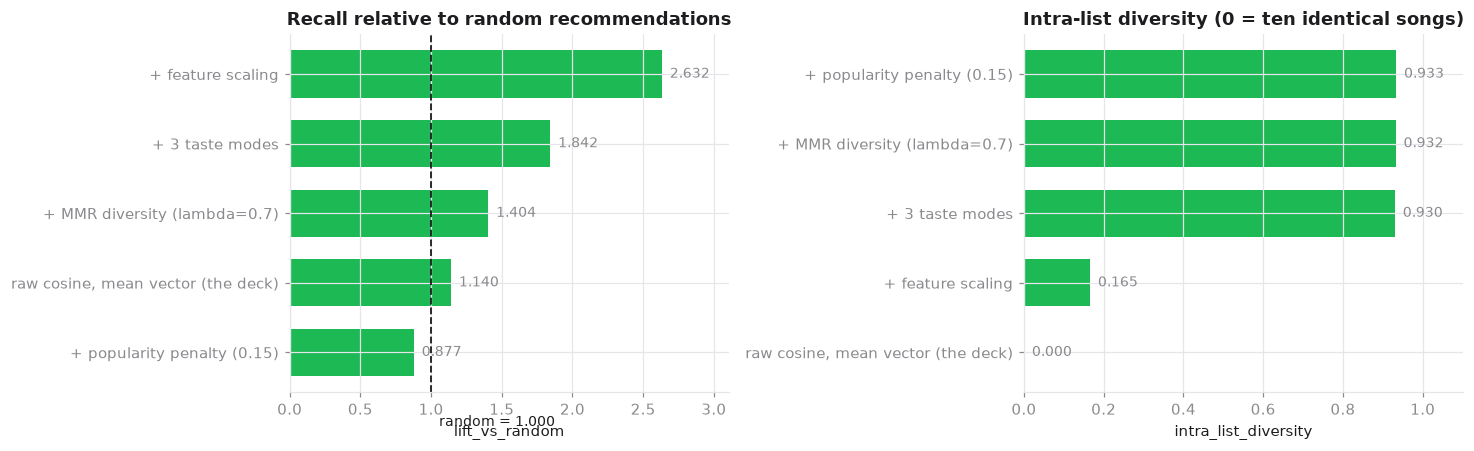

In [8]:
fig, axes = plt.subplots(1, 2, figsize=(13.5, 4.2))
d = ablation.reset_index()
d["short"] = [c.split(". ", 1)[1] for c in d["config"]]

viz.bar_results(d, "lift_vs_random", "short", "Recall relative to random recommendations",
                reference=1.0, reference_label="random", ax=axes[0])
viz.bar_results(d, "intra_list_diversity", "short", "Intra-list diversity (0 = ten identical songs)",
                ax=axes[1])
plt.tight_layout(); plt.show()

## 3 · Why the mean vector is the wrong query

The deepest of the three bugs, and the one that survives even after scaling.

Construct two users by hand. One listens only to pop. The other splits their listening
between ambient and metal — two genres about as far apart as the feature space allows.
Both get collapsed to a single average.

In [9]:
def build_user(uid, genres, n=150):
    pool = catalog[catalog[S.GENRE].isin(genres)]
    t = pool.sample(n=min(n, len(pool)), random_state=1).copy()
    t.insert(0, S.USER_ID, uid)
    return t

bimodal  = build_user("BIMODAL",  ["ambient", "metal"])
unimodal = build_user("UNIMODAL", ["pop"])
rec = R.Recommender(catalog, scale_features=True)

for name, uu in [("bimodal (ambient + metal)", bimodal), ("unimodal (pop)", unimodal)]:
    Z = rec._embed(uu)
    m = Z.mean(axis=0)
    nearest_own = np.linalg.norm(Z - m, axis=1).min()
    sub = Z[np.random.default_rng(3).choice(len(Z), min(120, len(Z)), replace=False)]
    pw = np.linalg.norm(sub[:, None, :] - sub[None, :, :], axis=-1)
    median_pairwise = np.median(pw[np.triu_indices(len(sub), 1)])
    print(f"{name}")
    print(f"   distance from the mean vector to their OWN nearest track : {nearest_own:.3f}")
    print(f"   median distance between two of their own tracks          : {median_pairwise:.3f}")
    modes = rec.mode_vectors(uu, k=3)
    dm = [np.linalg.norm(Z - c, axis=1).min() for c in modes]
    print(f"   same distance, from each of 3 mode centroids             : "
          f"{', '.join(f'{x:.3f}' for x in dm)}")
    print()

bimodal (ambient + metal)
   distance from the mean vector to their OWN nearest track : 2.050
   median distance between two of their own tracks          : 4.624
   same distance, from each of 3 mode centroids             : 1.378, 1.173, 0.859

unimodal (pop)
   distance from the mean vector to their OWN nearest track : 0.850
   median distance between two of their own tracks          : 2.558
   same distance, from each of 3 mode centroids             : 0.733, 0.837, 0.920



The bimodal user's mean vector sits **2.4× further from their nearest real
track** than the unimodal user's does. It is a point in feature space where they have
listened to nothing. The three mode centroids land between 0.86 and 1.38 — inside
actual music.

That is the geometry. Here is what it does to the recommendations, which is the part
that matters.

In [10]:
for name, uu, own in [("bimodal (ambient + metal)", bimodal, {"ambient", "metal"}),
                      ("unimodal (pop)", unimodal, {"pop"})]:
    print(f"=== {name} ===")
    for label, r in [("mean vector  ", rec.recommend(uu, n=20, modes=1)),
                     ("3 taste modes", rec.recommend(uu, n=20, modes=3))]:
        frac = r[S.GENRE].isin(own).mean()
        mix = ", ".join(f"{g} {n}" for g, n in r[S.GENRE].value_counts().head(4).items())
        print(f"  {label} -> {frac:5.0%} in a genre they listen to   [{mix}]")
    print()

=== bimodal (ambient + metal) ===
  mean vector   ->   45% in a genre they listen to   [ambient 9, classical 6, jazz 3, indie 2]
  3 taste modes ->   95% in a genre they listen to   [metal 13, ambient 6, classical 1]

=== unimodal (pop) ===
  mean vector   ->   10% in a genre they listen to   [latin 14, pop 2, rnb 2, rock 1]
  3 taste modes ->   25% in a genre they listen to   [latin 10, pop 5, edm 4, country 1]



Read the bimodal row carefully. Querying from the mean vector returns **9
ambient, 6 classical, 3 jazz, 2 indie — and zero metal**, to a user whose library is
half metal. Averaging did not blur that half of their taste; it deleted it, and then
filled the gap with classical and jazz, genres they never listen to at all.

Switching to three taste modes takes on-genre recommendations from 45% to 95% and puts
metal back as the largest category.

The unimodal user is a useful caution against reading too much into this metric: their
mean-vector recommendations are only 10% pop, mostly latin. In this catalog latin and
pop occupy neighbouring regions of feature space, so audio-feature retrieval crosses
between them freely. Genre overlap is a proxy for recommendation quality, not a
definition of it — but a proxy that goes to **zero metal for a metal listener** is
telling you something real.

## 4 · Sweeping the knobs, not guessing them

The ablation tested one setting of each parameter. A single point cannot distinguish "a
bad idea" from "a good idea at the wrong value", so sweep both.

In [11]:
sweep_listens = listens[listens[S.USER_ID].isin(sorted(listens[S.USER_ID].unique())[:80])]
rec = R.Recommender(catalog, scale_features=True)
SEEDS = range(5)

pop_rows = []
for pp in [0.0, 0.05, 0.1, 0.2, 0.4]:
    runs = [R.holdout_evaluation(rec, sweep_listens, n=20, seed=s_, modes=3,
                                 mmr_lambda=1.0, popularity_penalty=pp) for s_ in SEEDS]
    lifts = np.array([r["lift_vs_random"] for r in runs])
    pop_rows.append({"popularity_penalty": pp, "lift": lifts.mean(), "lift_std": lifts.std(),
                     "diversity": np.mean([r["intra_list_diversity"] for r in runs]),
                     "mean_rec_popularity": np.mean([r["mean_rec_popularity"] for r in runs])})
pd.DataFrame(pop_rows).round(3)

,popularity_penalty,lift,lift_std,diversity,mean_rec_popularity
0,0.00,2.447,0.387,0.914,24.284
1,0.05,1.711,0.220,0.914,16.470
2,0.10,1.263,0.158,0.914,12.492
3,0.20,1.105,0.105,0.915,8.943
4,0.40,0.921,0.118,0.916,5.974


In [12]:
mmr_rows = []
for ml in [1.0, 0.7, 0.5, 0.3]:
    runs = [R.holdout_evaluation(rec, sweep_listens, n=20, seed=s_, modes=3,
                                 mmr_lambda=ml, popularity_penalty=0.0) for s_ in SEEDS]
    lifts = np.array([r["lift_vs_random"] for r in runs])
    divs = np.array([r["intra_list_diversity"] for r in runs])
    mmr_rows.append({"mmr_lambda": ml, "lift": lifts.mean(), "lift_std": lifts.std(),
                     "diversity": divs.mean(), "diversity_std": divs.std()})
pd.DataFrame(mmr_rows).round(3)

,mmr_lambda,lift,lift_std,diversity,diversity_std
0,1.0,2.447,0.387,0.914,0.003
1,0.7,2.421,0.413,0.917,0.004
2,0.5,2.395,0.268,0.926,0.002
3,0.3,2.026,0.359,0.935,0.003


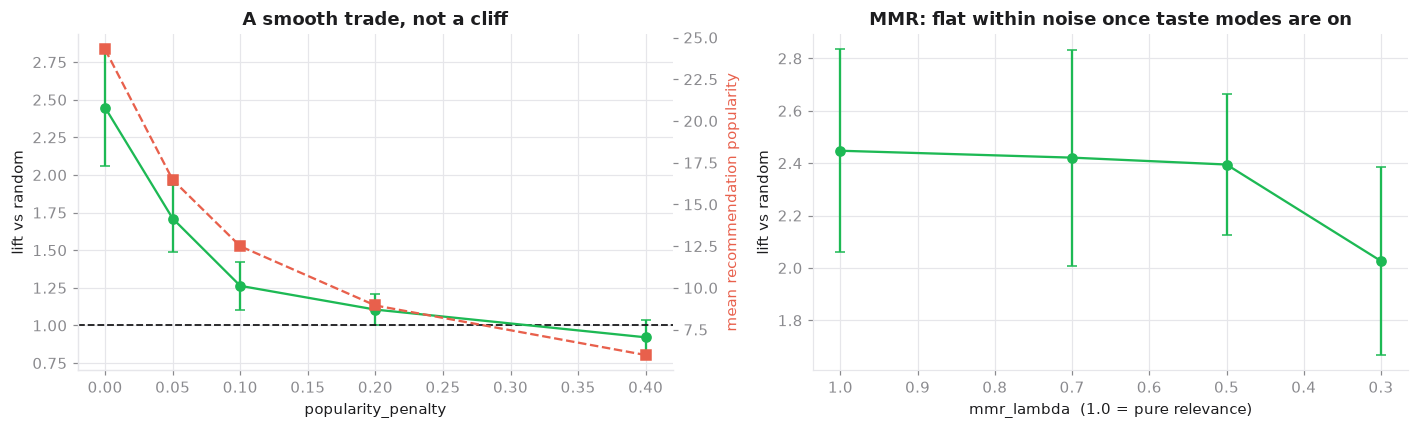

In [13]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
p = pd.DataFrame(pop_rows)
ax = axes[0]
ax.errorbar(p["popularity_penalty"], p["lift"], yerr=p["lift_std"], fmt="o-",
            color=viz.ACCENT, capsize=3)
ax.axhline(1.0, color=viz.INK, ls="--", lw=1.2)
ax.set_xlabel("popularity_penalty"); ax.set_ylabel("lift vs random")
ax.set_title("A smooth trade, not a cliff")
ax2 = ax.twinx(); ax2.grid(False)
ax2.plot(p["popularity_penalty"], p["mean_rec_popularity"], "s--", color=viz.WARN)
ax2.set_ylabel("mean recommendation popularity", color=viz.WARN)

m_ = pd.DataFrame(mmr_rows)
axes[1].errorbar(m_["mmr_lambda"], m_["lift"], yerr=m_["lift_std"], fmt="o-",
                 color=viz.ACCENT, capsize=3, label="lift vs random")
axes[1].set_xlabel("mmr_lambda  (1.0 = pure relevance)"); axes[1].set_ylabel("lift vs random")
axes[1].set_title("MMR: flat within noise once taste modes are on")
axes[1].invert_xaxis()
plt.tight_layout(); plt.show()

Both knobs now have error bars, which changes what can be claimed about them.

**The popularity penalty is a smooth dial.** Lift falls 2.45 → 1.71 → 1.26 → 1.11 →
0.92 as the penalty rises, while mean recommendation popularity falls 24 → 17 → 13 → 9
→ 6. There is no free setting and no cliff: the first notch costs about 30% of the
accuracy and buys about a third off the popularity. That is a legitimate product
trade, and it belongs behind a user-facing "show me deeper cuts" toggle where the user
is the one choosing to pay for it — not in the default configuration.

(The single-seed version of this sweep appeared to show no cost at all at 0.05. It was
noise. Lift carries a standard deviation of roughly ±0.3 across holdout seeds, which is
large enough to invent a free lunch if you only look once.)

**MMR does nothing measurable here.** Lift is flat within its error bars across the
whole range — 2.45 ± 0.39 down to 2.03 ± 0.36 — and diversity moves only from 0.914 to
0.935. The taste modes already produce diversity of 0.91; three queries aimed at three
different regions of feature space cannot return ten near-identical songs, so MMR
arrives with nothing left to fix. It can be dropped and the computation saved.

## 5 · What recall@20 can and cannot tell you

Every number above rests on one metric, so it is worth being explicit about its
limits.

A note on which number to quote, because there are two. The single-seed ablation in
§2 and the six-seed replication immediately after it disagree by about 15% — one
holdout split is a noisy estimate. **Everything from here on quotes the six-seed
mean**, since that is the one with an error bar attached. The cell below recomputes
the headline ratio on that basis so the two agree.

**It is tiny by construction.** Twenty recommendations drawn from 8,000 songs gives a
random baseline of 0.25%. A recall under 1% sounds like failure and is in fact
several times random. The absolute value is meaningless; only the ratio is worth
reading.

**It rewards predicting what the user already likes.** The held-out tracks come from
the same library — the same genre mixture, the same artists — as the tracks used to
build the profile. A system that recommends more of exactly what someone already
listens to scores perfectly. A system that finds them something genuinely new scores
zero for it.

That is why taste modes "losing" recall should be read carefully. Modes spread the
query across the user's whole taste, including its thinner edges, where there are
fewer held-out tracks to hit. The metric penalises that. A listener probably would
not.

**What would measure the real thing:** thumbs up/down on served recommendations. The
deck's own future-work slide proposed exactly that, and it remains the right next step
— it is the only way to distinguish "we predicted your library" from "we found you
something good."

In [14]:
random_baseline = 20 / len(catalog)
best_seeded = ablation_seeds["recall@20 mean"].max()
best_single = ablation["recall@20"].max()

print(f"catalog size                      : {len(catalog):,}")
print(f"random recall@20                  : {random_baseline:.5f}")
print()
print(f"best config, six-seed mean        : {best_seeded:.5f}"
      f"   ->  {best_seeded / random_baseline:.2f}x random      <- quote this one")
print(f"best config, single ablation split: {best_single:.5f}"
      f"   ->  {best_single / random_baseline:.2f}x random")
print()
print(f"the two bases differ by {abs(best_seeded - best_single) / best_single:.0%} "
      "-- which is why the seeded one is the one reported.")
print("Report the ratio either way. The raw recall number means nothing on its own.")

catalog size                      : 8,000
random recall@20                  : 0.00250

best config, six-seed mean        : 0.00775   ->  3.10x random      <- quote this one
best config, single ablation split: 0.00658   ->  2.63x random

the two bases differ by 18% -- which is why the seeded one is the one reported.
Report the ratio either way. The raw recall number means nothing on its own.


## Verdict

| claim | status |
|---|---|
| Cosine over raw audio features finds similar songs | **no** — 99% of the catalog scores >0.999999; the function is saturated |
| The recommendations were at least driven by the data | **barely** — a 1% imperceptible perturbation changes 8 of the top 10 |
| Scaling is a cosmetic fix | **no** — it is the single biggest win, 1.3× to 3.1× random (six-seed means) |
| One mean vector represents a user | **no** — it recommends zero metal to a half-metal listener |
| Taste modes improve recall | **no** — they cost ~⅓ of it, and buy 5.6× the diversity |
| MMR adds diversity | **not on top of taste modes** — flat within noise; drop it |
| A popularity penalty is a free discovery win | **no** — a smooth trade: ~30% of accuracy for ~⅓ off popularity. Make it a user-facing toggle |

### Recommended configuration

`scale_features=True, modes=3, mmr_lambda=1.0, popularity_penalty=0.0` — with the
penalty exposed as an optional "dig deeper" toggle rather than a default.

`service.LovifyModels` **now defaults to `mmr_lambda=1.0`**, changed on this evidence.
An earlier version of this notebook flagged the old default of 0.7 as costing
computation for no measurable gain; that has since been applied.

→ `04_end_to_end.ipynb` assembles this with the other two models into one service.